In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sentence_transformers import SentenceTransformer

# Works regardless of where Jupyter is launched from
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CORPUS_PATH = PROJECT_ROOT / "data" / "processed" / "corpus.txt"

# Verify before loading
print(f"Project root: {PROJECT_ROOT}")
print(f"Corpus path: {CORPUS_PATH}")
print(f"Exists: {CORPUS_PATH.exists()}")

with open(CORPUS_PATH) as f:
    all_sentences = [line.strip() for line in f.readlines()]

print(f"\nCorpus loaded: {len(all_sentences)} sentences")
print(all_sentences[0])
print(all_sentences[1000])
print(all_sentences[25000])

Project root: /home/humza/projects/f1-rag
Corpus path: /home/humza/projects/f1-rag/data/processed/corpus.txt
Exists: True

Corpus loaded: 28315 sentences
In the 1950 British Grand Prix, Nino Farina finished 1st (winner) starting from position 1, scoring 9.0 points for Alfa Romeo.
In the 1954 Spanish Grand Prix, Paco Godia finished 6th starting from position 13, scoring 0.0 points for Maserati.
In the 2024 Chinese Grand Prix, Fernando Alonso finished 7th starting from position 3, scoring 7.0 points for Aston Martin and set the fastest lap.


In [2]:
# This downloads ~90MB on first run, cached after that
model = SentenceTransformer("all-MiniLM-L6-v2")

print(f"Model loaded: {model}")
print(f"Embedding dimensions: {model.get_embedding_dimension()}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({})
)
Embedding dimensions: 384


In [3]:
# Embed just 3 sentences and look at the raw vectors
sample_sentences = [
    all_sentences[0],   # a result sentence
    all_sentences[25939],  # a standings sentence
    "Lewis Hamilton won the 2020 British Grand Prix starting from pole position."
]

embeddings = model.encode(sample_sentences)

print(f"Shape of embeddings: {embeddings.shape}")
print(f"Each sentence becomes a vector of {embeddings.shape[1]} numbers\n")

print(f"Sentence: '{sample_sentences[0]}'")
print(f"First 10 values of its vector:")
print(embeddings[0][:10])
print(f"\nMin value: {embeddings[0].min():.4f}")
print(f"Max value: {embeddings[0].max():.4f}")

Shape of embeddings: (3, 384)
Each sentence becomes a vector of 384 numbers

Sentence: 'In the 1950 British Grand Prix, Nino Farina finished 1st (winner) starting from position 1, scoring 9.0 points for Alfa Romeo.'
First 10 values of its vector:
[ 0.00258926  0.0106371  -0.02636002  0.02134801  0.04086629  0.08514454
 -0.0609555   0.08347778 -0.02465656 -0.07401638]

Min value: -0.1240
Max value: 0.1325


In [4]:
# This is the math behind every RAG retrieval
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Three test sentences
hamilton_win = "Lewis Hamilton finished 1st starting from position 1, scoring 25 points for Mercedes."
verstappen_win = "Max Verstappen finished 1st starting from position 1, scoring 25 points for Red Bull."
hamilton_dnf = "Lewis Hamilton retired (engine) starting from position 3, scoring 0 points for Mercedes."
unrelated = "The 2020 constructors championship was won by Mercedes with 573 points."

sentences = [hamilton_win, verstappen_win, hamilton_dnf, unrelated]
vecs = model.encode(sentences)

print("Cosine similarity scores:\n")
print(f"Hamilton win vs Verstappen win:  {cosine_similarity(vecs[0], vecs[1]):.4f}")
print(f"Hamilton win vs Hamilton DNF:    {cosine_similarity(vecs[0], vecs[2]):.4f}")
print(f"Hamilton win vs unrelated:       {cosine_similarity(vecs[0], vecs[3]):.4f}")

print("\nWhat this tells you:")
print("- Score near 1.0 = very similar meaning")
print("- Score near 0.0 = unrelated")
print("- RAG retrieval is just finding the highest scores against your query")

Cosine similarity scores:

Hamilton win vs Verstappen win:  0.5531
Hamilton win vs Hamilton DNF:    0.8207
Hamilton win vs unrelated:       0.4984

What this tells you:
- Score near 1.0 = very similar meaning
- Score near 0.0 = unrelated
- RAG retrieval is just finding the highest scores against your query


In [5]:
# Embed 3000 sentences — enough to see patterns, fast enough to run locally
# Take evenly spaced samples across the corpus
import random
random.seed(42)

sample_size = 3000
indices = sorted(random.sample(range(len(all_sentences)), sample_size))
sample_sentences = [all_sentences[i] for i in indices]

print(f"Embedding {sample_size} sentences...")
sample_embeddings = model.encode(sample_sentences, show_progress_bar=True, batch_size=64)
print(f"Done. Shape: {sample_embeddings.shape}")

Embedding 3000 sentences...


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Done. Shape: (3000, 384)


Running UMAP dimensionality reduction...


/home/humza/projects/f1-rag/venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Done.


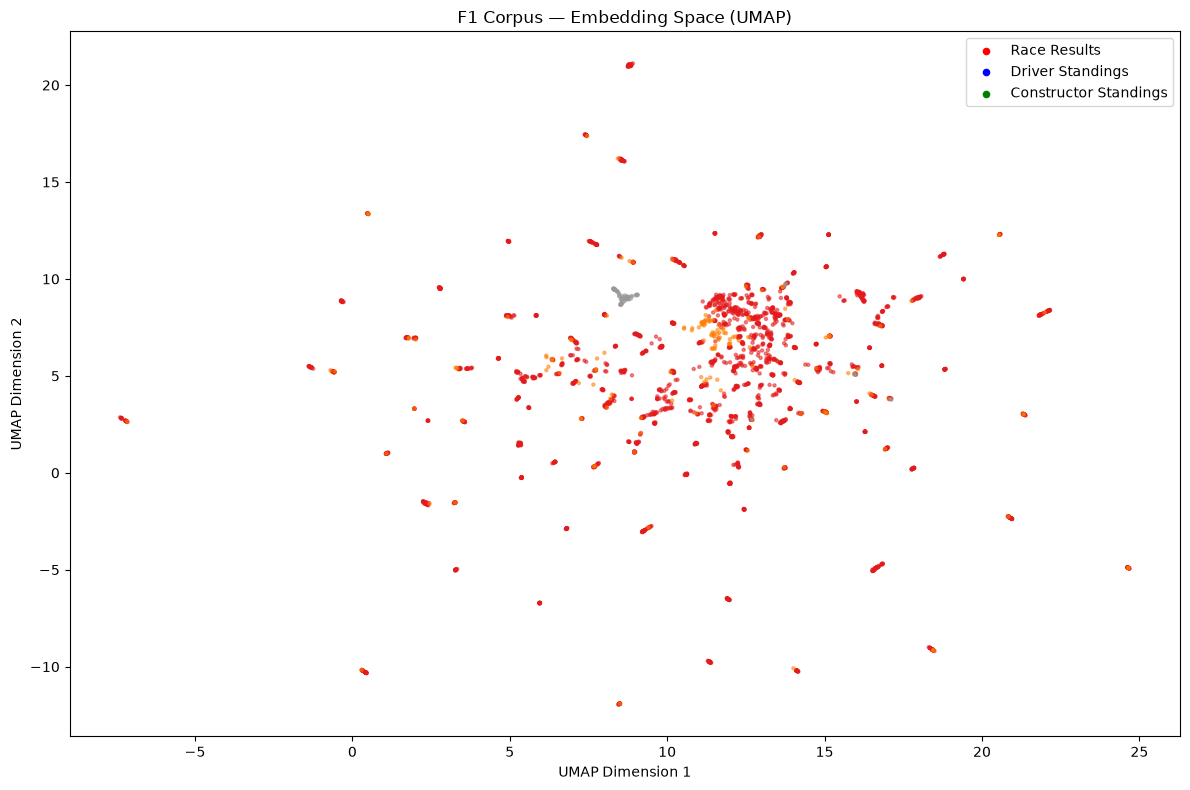

Plot saved.


In [6]:
import umap
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Label each sentence by type for colouring
def get_label(sentence):
    if "drivers championship" in sentence:
        return "driver_standing"
    elif "constructors championship" in sentence:
        return "constructor_standing"
    else:
        return "race_result"

labels = [get_label(s) for s in sample_sentences]
label_map = {"race_result": 0, "driver_standing": 1, "constructor_standing": 2}
colors = [label_map[l] for l in labels]

print("Running UMAP dimensionality reduction...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding_2d = reducer.fit_transform(sample_embeddings)
print("Done.")

# Plot
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embedding_2d[:, 0], 
    embedding_2d[:, 1],
    c=colors,
    cmap="Set1",
    alpha=0.5,
    s=5
)

# Legend
handles = [
    plt.scatter([], [], c="red", label="Race Results", s=20),
    plt.scatter([], [], c="blue", label="Driver Standings", s=20),
    plt.scatter([], [], c="green", label="Constructor Standings", s=20),
]
plt.legend(handles=handles)
plt.title("F1 Corpus — Embedding Space (UMAP)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.tight_layout()
plt.savefig(str(PROJECT_ROOT / "data" / "processed" / "umap_corpus.png"), dpi=150)
plt.show()
print("Plot saved.")

In [7]:
# Pick a specific driver and find their sentences by similarity
query = "Lewis Hamilton championship victory Mercedes dominant season"
query_vec = model.encode([query])[0]

# Score all sample sentences
scores = [cosine_similarity(query_vec, vec) for vec in sample_embeddings]
top_indices = np.argsort(scores)[::-1][:10]

print(f"Query: '{query}'\n")
print("Top 10 most similar sentences in the sample:\n")
for rank, idx in enumerate(top_indices):
    print(f"{rank+1}. [{scores[idx]:.4f}] {sample_sentences[idx]}")

Query: 'Lewis Hamilton championship victory Mercedes dominant season'

Top 10 most similar sentences in the sample:

1. [0.7675] At the end of the 2017 season, hamilton led the drivers championship with 363.0 points and 9 wins, driving for Mercedes.
2. [0.6614] In the 2018 German Grand Prix, Lewis Hamilton finished 1st (winner) starting from position 14, scoring 25.0 points for Mercedes and set the fastest lap.
3. [0.6521] In the 2017 British Grand Prix, Lewis Hamilton finished 1st (winner) starting from position 1, scoring 25.0 points for Mercedes and set the fastest lap.
4. [0.6509] In the 2016 Mexican Grand Prix, Lewis Hamilton finished 1st (winner) starting from position 1, scoring 25.0 points for Mercedes.
5. [0.6467] In the 2016 European Grand Prix, Lewis Hamilton finished 5th starting from position 10, scoring 10.0 points for Mercedes.
6. [0.6458] In the 2017 Spanish Grand Prix, Lewis Hamilton finished 1st (winner) starting from position 1, scoring 25.0 points for Mercedes and s

In [8]:
## What We Learned

#- An embedding is a vector of 384 numbers representing semantic meaning
#- Sentences with similar *meaning* have vectors that point in similar directions
- Cosine similarity measures the angle between vectors — this is retrieval
- The UMAP plot shows natural clustering by sentence type without any labels during training
- RAG retrieval = embed query → find nearest vectors → return those sentences as context

The model never saw F1 data during training.
The clusters formed purely from language understanding.

SyntaxError: invalid character '—' (U+2014) (2455107788.py, line 5)